# Lineer Regression / Tips Linear Regression

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** No local CSV/XLSX next to this notebook; see code for in-library/remote datasets..  
**Methods referenced:** `LinearRegression`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [4]:
df.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


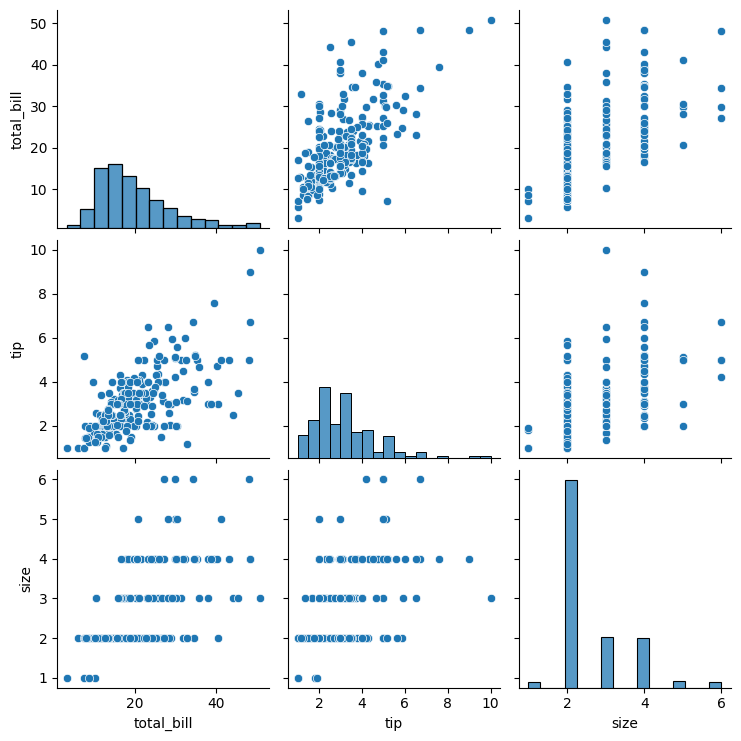

In [5]:
sns.pairplot(df)
plt.show()

In [6]:
df.corr(numeric_only = True)

,total_bill,tip,size
total_bill,1.000000,0.675734,0.598315
tip,0.675734,1.000000,0.489299
size,0.598315,0.489299,1.000000


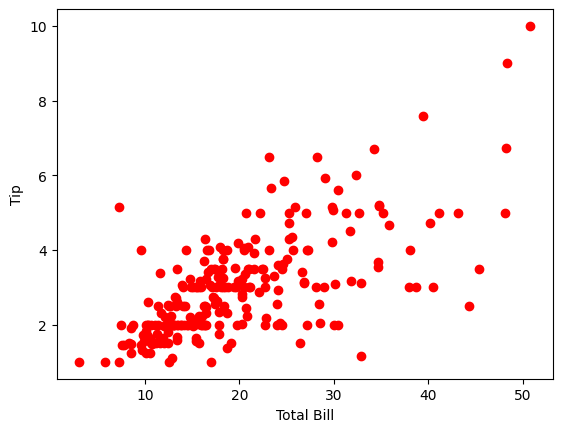

In [7]:
plt.scatter(df["total_bill"], df["tip"], color = "r")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()

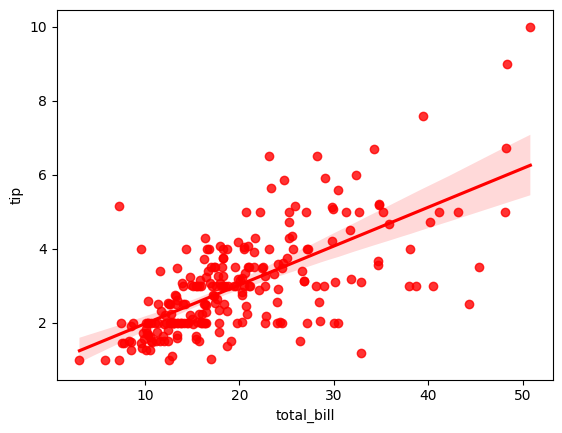

In [8]:
sns.regplot(x = df["total_bill"], y = df["tip"], color = "r")
plt.show()

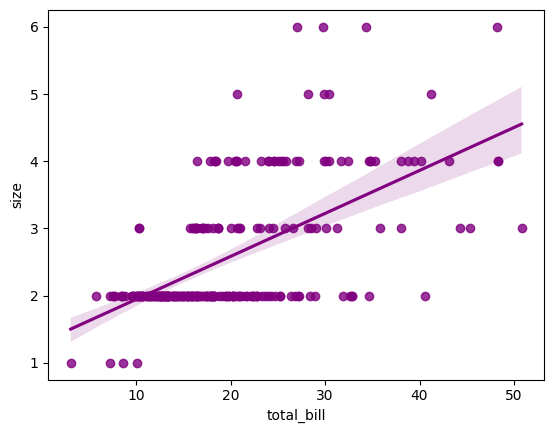

In [9]:
sns.regplot(x = df["total_bill"], y = df["size"], color = "purple")
plt.show()

### independent and dependent features

In [10]:
X = df[["total_bill", "size"]]
y = df["tip"]

In [11]:
X.head()

,total_bill,size
0,16.99,2
1,10.34,3
2,21.01,3
3,23.68,2
4,24.59,4


In [12]:
y.head()

0    1.01
1    1.66
2    3.50
3    3.31
4    3.61
Name: tip, dtype: float64

### train - test split

In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 15)

In [15]:
from sklearn.preprocessing import StandardScaler

In [16]:
scaler = StandardScaler()

In [17]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
X_train

array([[-6.19165645e-02, -6.56762781e-01],
       [-1.24856603e+00, -6.56762781e-01],
       [-6.53027401e-01, -6.56762781e-01],
       [-6.40850960e-01, -6.56762781e-01],
       [-4.43814015e-01,  3.79337124e-01],
       [ 1.61621832e+00,  1.41543703e+00],
       [-1.02717621e+00, -6.56762781e-01],
       [-7.49331975e-01, -6.56762781e-01],
       [-3.57471983e-01, -6.56762781e-01],
       [ 9.41632630e-02,  3.79337124e-01],
       [-8.37887905e-01, -6.56762781e-01],
       [ 3.37692072e-01,  3.79337124e-01],
       [-1.14783366e+00, -6.56762781e-01],
       [-1.07588197e+00, -6.56762781e-01],
       [ 1.36715476e+00,  1.41543703e+00],
       [ 3.06697496e-01,  3.79337124e-01],
       [-1.13676417e+00, -6.56762781e-01],
       [ 2.22725424e+00,  1.41543703e+00],
       [-1.41682230e+00, -6.56762781e-01],
       [-1.38250688e+00, -6.56762781e-01],
       [-2.46777069e-01, -6.56762781e-01],
       [-4.82557234e-01,  3.79337124e-01],
       [ 2.34016305e+00,  2.45153693e+00],
       [-2.

In [19]:
from sklearn.linear_model import LinearRegression

In [20]:
regression = LinearRegression()

In [21]:
regression.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [23]:
twenty_dolar_scaled = scaler.transform([[20, 3]])

c:\Users\emres\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [24]:
real_prediction = regression.predict(twenty_dolar_scaled)
print("real prediction: ", real_prediction)

real prediction:  [3.11972541]


### prediction

In [25]:
y_pred = regression.predict(X_test)

In [26]:
y_pred

array([2.42425224, 1.68625429, 2.35861617, 2.59065357, 3.60165022,
       4.22657963, 1.9647997 , 2.28650893, 2.11456089, 2.73856585,
       2.89693253, 5.92757092, 3.00111016, 2.32256255, 2.7786027 ,
       2.87908252, 2.28373557, 5.0400972 , 3.18507606, 4.46444916,
       1.61350803, 2.40483876, 4.39113205, 3.4124912 , 2.60082253,
       2.19406375, 2.16263239, 3.17768045, 1.5633022 , 2.61468931,
       2.38265191, 2.27449105, 2.99862223, 2.7357925 , 3.95450538,
       2.76999721, 2.74809579, 2.74965927, 2.97614996, 4.59230893,
       2.47232374, 3.32559274, 2.56107111, 2.5074529 , 3.21309504,
       1.77621154, 3.29601028, 2.12103206, 2.81806871, 2.31794029,
       2.44828799, 2.5037551 , 2.99399997, 2.25969983, 2.47417264,
       2.95766092, 4.11692347, 3.18600052, 2.32256255, 3.23869427,
       5.46321069])

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [28]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("mse: ", mse)
print("mae: ", mae)

mse:  1.2979296770598863
mae:  0.8505530977339807


In [29]:
score = r2_score(y_test, y_pred)
print("r2 score: ", score)

r2 score:  0.3815069874498642


In [30]:
regression.intercept_

np.float64(3.0551366120218577)

In [31]:
regression.coef_

array([0.83513484, 0.18229284])

In [32]:
1 - (1 - score) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

0.3601796421895147